# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Rafi Ul Aziz
- NIM   : 241011400557
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# Import library utama sesuai ketentuan tugas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 57
np.set_printoptions(precision=4, suppress=True)
print("Identitas: Rafi Ul Aziz | NIM: 241011400557 | Kelas: Reg B")
print("Random state:", RANDOM_STATE)

Identitas: Rafi Ul Aziz | NIM: 241011400557 | Kelas: Reg B
Random state: 57


In [2]:
# Pembagian data manual, mengikuti pola materi dosen.
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)
    if len(X) != len(y):
        raise ValueError("X dan y harus memiliki jumlah baris yang sama")
    if not 0 < test_size < 1:
        raise ValueError("test_size harus di antara 0 dan 1")
    n_total = len(X)
    n_test = int(round(n_total * test_size))
    rng = np.random.RandomState(random_state) if random_state is not None else np.random
    indices = rng.permutation(n_total)
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

Lima baris pertama:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


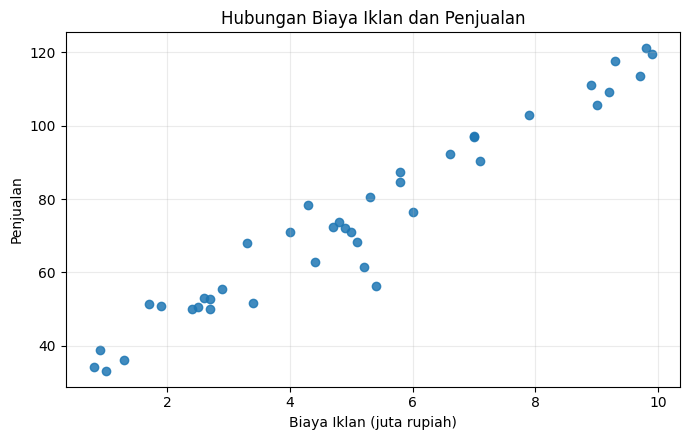

In [3]:
# Jawaban A1
ads_data = pd.read_csv('Ads_Data.csv')
print("Lima baris pertama:")
display(ads_data.head())
print("Jumlah baris data:", len(ads_data))
X = ads_data[['BiayaIklan']].to_numpy(dtype=float)
y = ads_data['Penjualan'].to_numpy(dtype=float)
print("Shape X:", X.shape, "| Shape y:", y.shape)
assert X.ndim == 2 and X.shape[1] == 1
plt.figure(figsize=(7, 4.5))
plt.scatter(X[:, 0], y, alpha=0.85)
plt.title('Hubungan Biaya Iklan dan Penjualan')
plt.xlabel('Biaya Iklan (juta rupiah)')
plt.ylabel('Penjualan')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3: Linear Regression dengan Normal Equation.
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_, self.coefficients_ = float(beta[0]), beta[1:]
        return self
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_

regressor = LinearRegression().fit(X_train, y_train)
print(f"Intercept (b): {regressor.intercept_:.6f}")
print(f"Koefisien (m): {regressor.coefficients_[0]:.6f}")
print(f"Persamaan: ŷ = {regressor.intercept_:.4f} + {regressor.coefficients_[0]:.4f}X")

Intercept (b): 28.639425
Koefisien (m): 8.965915
Persamaan: ŷ = 28.6394 + 8.9659X


**Jawaban A3 (interpretasi):**

Koefisien positif berarti model memperkirakan penjualan meningkat ketika biaya iklan meningkat. Setiap kenaikan biaya iklan sebesar 1 juta rupiah berkaitan dengan kenaikan penjualan sebesar nilai koefisien model, dengan asumsi hubungan linear pada data ini.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4: metrik regresi dihitung manual menggunakan NumPy.
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    error = y_true - y_pred
    mae = np.mean(np.abs(error))
    mse = np.mean(error ** 2)
    rmse = np.sqrt(mse)
    ss_res = np.sum(error ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R²': r2}

y_train_pred = regressor.predict(X_train)
y_test_pred = regressor.predict(X_test)
regression_results = pd.DataFrame([
    {'Dataset': 'Training', **regression_metrics(y_train, y_train_pred)},
    {'Dataset': 'Testing', **regression_metrics(y_test, y_test_pred)}
]).set_index('Dataset')
display(regression_results.round(4))

,MAE,MSE,RMSE,R²
Dataset,,,,
Training,4.8684,41.6536,6.4540,0.9378
Testing,3.3922,14.7946,3.8464,0.9668


**Jawaban A4 (analisis):**

RMSE menggambarkan besar kesalahan prediksi dalam satuan target penjualan; semakin kecil nilainya, semakin dekat prediksi terhadap nilai aktual. Nilai R² menunjukkan proporsi variasi target yang dapat dijelaskan model. Penilaian baik atau tidak perlu melihat metrik testing dan konteks masalah, bukan hanya hasil training.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

,Learning rate,Intercept,Koefisien,MSE akhir,Iterasi dijalankan,Status
0,0.001,2.056597e+01,1.021656e+01,57.57402,5000,konvergen
1,0.020,2.863943e+01,8.965910e+00,41.65358,5000,konvergen
2,0.100,2.845121e+48,1.836644e+49,inf,135,divergen


Normal Equation: b=28.63943, m=8.96591


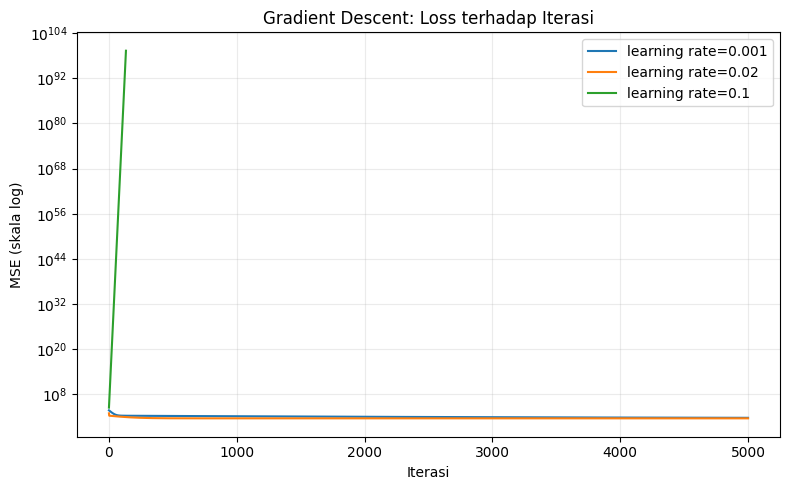

In [7]:
# Jawaban A5: Gradient Descent mengikuti rumus materi (fitur tidak diskalakan).
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.converged_ = True
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        if X.ndim == 1: X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])
        self.loss_history_ = []
        self.converged_ = True
        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient
            # Hentikan divergensi sebelum angka tak hingga merusak seluruh notebook.
            if not np.all(np.isfinite(beta)) or np.max(np.abs(beta)) > 1e50:
                self.converged_ = False
                self.loss_history_.append(np.inf)
                break
            loss = np.mean((y - X_b @ beta) ** 2)
            if not np.isfinite(loss) or loss > 1e100:
                self.converged_ = False
                self.loss_history_.append(np.inf)
                break
            self.loss_history_.append(float(loss))
        self.intercept_ = float(beta[0])
        self.coefficients_ = beta[1:]
        return self
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1: X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_

learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
gd_rows = []
for lr in learning_rates:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model
    finite_losses = np.asarray(model.loss_history_, dtype=float)
    final_loss = finite_losses[-1] if len(finite_losses) else np.nan
    gd_rows.append({'Learning rate': lr, 'Intercept': model.intercept_, 'Koefisien': model.coefficients_[0],
                    'MSE akhir': final_loss, 'Iterasi dijalankan': len(model.loss_history_),
                    'Status': 'konvergen' if model.converged_ else 'divergen'})
display(pd.DataFrame(gd_rows).round(5))
print(f"Normal Equation: b={regressor.intercept_:.5f}, m={regressor.coefficients_[0]:.5f}")
plt.figure(figsize=(8, 5))
for lr, model in gd_models.items():
    losses = np.asarray(model.loss_history_, dtype=float)
    valid = np.isfinite(losses) & (losses > 0)
    if valid.any(): plt.plot(np.arange(1, len(losses)+1)[valid], losses[valid], label=f'learning rate={lr}')
plt.yscale('log'); plt.xlabel('Iterasi'); plt.ylabel('MSE (skala log)')
plt.title('Gradient Descent: Loss terhadap Iterasi'); plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

**Jawaban A5 (analisis):**

Learning rate 0.001 melakukan pembaruan kecil sehingga penurunan loss lebih lambat. Learning rate 0.02 umumnya memberikan langkah yang cukup besar untuk mendekati solusi Normal Equation. Learning rate 0.1 terlalu besar untuk skala fitur asli pada dataset ini sehingga pembaruan dapat melampaui minimum dan mengalami divergensi. Status, jumlah iterasi, dan grafik loss di atas memperlihatkan hasil aktual; divergensi tidak dianggap sebagai model yang berhasil konvergen.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

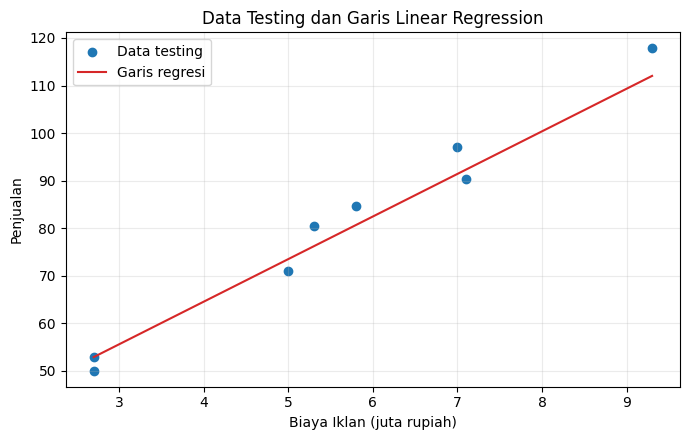

,Biaya Iklan (juta Rp),Prediksi Penjualan
0,4.5,68.986
1,7.0,91.401
2,12.0,136.230


In [8]:
# Jawaban A6
order = np.argsort(X_test[:, 0])
plt.figure(figsize=(7, 4.5))
plt.scatter(X_test[:, 0], y_test, label='Data testing', color='tab:blue')
plt.plot(X_test[order, 0], y_test_pred[order], color='tab:red', label='Garis regresi')
plt.title('Data Testing dan Garis Linear Regression')
plt.xlabel('Biaya Iklan (juta rupiah)')
plt.ylabel('Penjualan')
plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()
biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = regressor.predict(biaya_baru)
prediksi_ads = pd.DataFrame({'Biaya Iklan (juta Rp)': biaya_baru[:, 0], 'Prediksi Penjualan': prediksi_penjualan})
display(prediksi_ads.round(3))

**Jawaban A6 (analisis):**

Prediksi pada biaya iklan 4,5 dan 7 juta berada lebih dekat dengan rentang data yang diamati sehingga umumnya lebih dapat dipercaya. Prediksi untuk 12 juta merupakan ekstrapolasi karena melampaui rentang biaya iklan pada dataset. Hubungan linear belum tentu terus berlaku di luar data, sehingga prediksi 12 juta perlu diperlakukan lebih hati-hati dan tidak dianggap sebagai kepastian.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

Lima baris pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah baris: 60
Jumlah label Spam (1) dan Bukan Spam (0):


,Jumlah
Kelas,
Bukan Spam,35
Spam,25


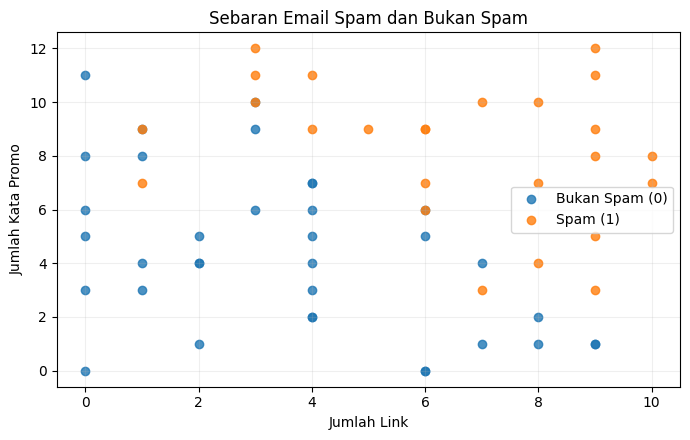

In [9]:
# Jawaban B1
email_data = pd.read_csv('Email_Data.csv')
print('Lima baris pertama:')
display(email_data.head())
print('Jumlah baris:', len(email_data))
print('Jumlah label Spam (1) dan Bukan Spam (0):')
display(email_data['Spam'].map({0:'Bukan Spam', 1:'Spam'}).value_counts().rename_axis('Kelas').to_frame('Jumlah'))
X_email = email_data[['JumlahLink', 'KataPromo']].to_numpy(dtype=float)
y_email = email_data['Spam'].to_numpy(dtype=int)
plt.figure(figsize=(7, 4.5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], label='Bukan Spam (0)', alpha=0.8)
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], label='Spam (1)', alpha=0.8)
plt.xlabel('Jumlah Link'); plt.ylabel('Jumlah Kata Promo')
plt.title('Sebaran Email Spam dan Bukan Spam'); plt.legend(); plt.grid(alpha=0.2); plt.tight_layout(); plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Shape train/test: (45, 2) (15, 2)
Intercept (b): -12.152776
Koefisien (m1, m2): [1.0709 1.0824]
P(Spam) = sigmoid(-12.1528 + (1.0709)*JumlahLink + (1.0824)*KataPromo)


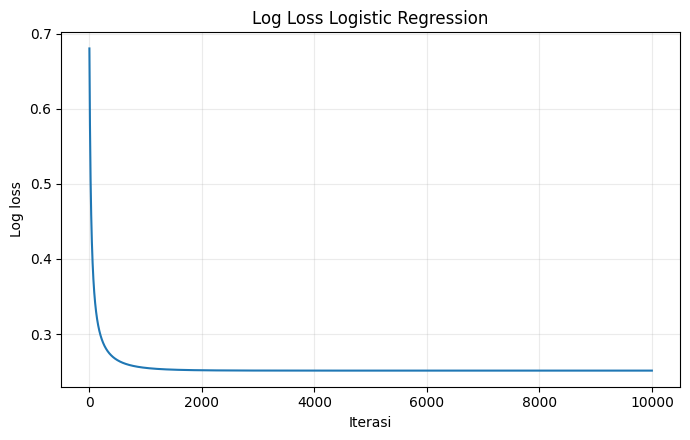

Log loss awal: 0.680134; akhir: 0.251342


In [10]:
# Jawaban B2: Logistic Regression dengan gradient descent.
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.mu_ = None
        self.sigma_ = None
    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))
    def fit(self, X, y):
        X = np.asarray(X, dtype=float); y = np.asarray(y, dtype=float).reshape(-1)
        if X.ndim == 1: X = X.reshape(-1, 1)
        # Standardisasi berdasarkan data training saja agar GD stabil.
        self.mu_ = X.mean(axis=0); self.sigma_ = X.std(axis=0)
        self.sigma_[self.sigma_ == 0] = 1.0
        Xs = (X - self.mu_) / self.sigma_
        Xb = np.c_[np.ones(len(Xs)), Xs]
        beta = np.zeros(Xb.shape[1]); self.loss_history_ = []
        for _ in range(self.n_iterations):
            p = self._sigmoid(Xb @ beta)
            grad = Xb.T @ (p - y) / len(y)
            beta -= self.learning_rate * grad
            p2 = np.clip(self._sigmoid(Xb @ beta), 1e-15, 1 - 1e-15)
            loss = -np.mean(y*np.log(p2) + (1-y)*np.log(1-p2))
            self.loss_history_.append(float(loss))
        self.coefficients_ = beta[1:] / self.sigma_
        self.intercept_ = float(beta[0] - np.sum(beta[1:] * self.mu_ / self.sigma_))
        return self
    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1: X = X.reshape(1, -1)
        return self._sigmoid(self.intercept_ + X @ self.coefficients_)
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)
classifier = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X_train_email, y_train_email)
print('Shape train/test:', X_train_email.shape, X_test_email.shape)
print(f'Intercept (b): {classifier.intercept_:.6f}')
print('Koefisien (m1, m2):', classifier.coefficients_)
print(f'P(Spam) = sigmoid({classifier.intercept_:.4f} + ({classifier.coefficients_[0]:.4f})*JumlahLink + ({classifier.coefficients_[1]:.4f})*KataPromo)')
plt.figure(figsize=(7, 4.5))
plt.plot(np.arange(1, len(classifier.loss_history_)+1), classifier.loss_history_)
plt.xlabel('Iterasi'); plt.ylabel('Log loss'); plt.title('Log Loss Logistic Regression')
plt.grid(alpha=0.25); plt.tight_layout(); plt.show()
print(f'Log loss awal: {classifier.loss_history_[0]:.6f}; akhir: {classifier.loss_history_[-1]:.6f}')

**Jawaban B2 (analisis):**

Koefisien menunjukkan arah hubungan setiap fitur dengan probabilitas spam, dengan fitur lain dianggap tetap. Fungsi sigmoid mengubah kombinasi linear menjadi probabilitas antara 0 dan 1. Kurva log loss dan nilai awal/akhir di atas digunakan untuk menilai apakah proses training membaik dan mulai stabil.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3: seluruh metrik utama dihitung manual.
def accuracy_score(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))
def confusion_matrix(y_true, y_pred):
    yt = np.asarray(y_true, dtype=int); yp = np.asarray(y_pred, dtype=int)
    tn = np.sum((yt == 0) & (yp == 0)); fp = np.sum((yt == 0) & (yp == 1))
    fn = np.sum((yt == 1) & (yp == 0)); tp = np.sum((yt == 1) & (yp == 1))
    return np.array([[tn, fp], [fn, tp]])
def classification_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    return {'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision, 'Recall': recall, 'F1-score': f1}, cm

y_pred_email = classifier.predict(X_test_email, threshold=0.5)
metrics_email, cm_email = classification_metrics(y_test_email, y_pred_email)
print('Confusion matrix [[TN, FP], [FN, TP]]:')
print(cm_email)
display(pd.DataFrame([metrics_email], index=['Testing']).round(4))

Confusion matrix [[TN, FP], [FN, TP]]:
[[8 2]
 [1 4]]


,Accuracy,Precision,Recall,F1-score
Testing,0.8,0.6667,0.8,0.7273


**Jawaban B3 (analisis):**

False positive (FP) berarti email bukan spam keliru ditandai sebagai spam; pengguna mungkin kehilangan email penting. False negative (FN) berarti email spam lolos ke kotak masuk. Untuk penggunaan umum, FP dapat sangat merugikan jika email penting terlewat, sehingga filter sebaiknya mempertimbangkan keseimbangan precision dan recall serta menyediakan folder spam untuk pemeriksaan ulang.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

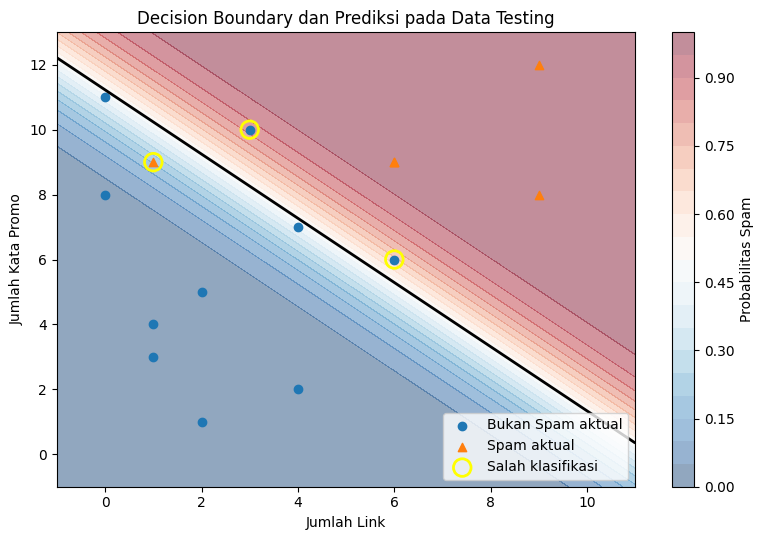

Baris testing yang salah diklasifikasikan (indeks lokal, aktual, prediksi):
[(6, 0, 1), (7, 1, 0), (13, 0, 1)]
Decision boundary: x2 = -(-12.1528 + (1.0709)*x1)/(1.0824)


In [12]:
# Jawaban B4: probabilitas, decision boundary, dan kesalahan klasifikasi.
x_min, x_max = X_email[:, 0].min()-1, X_email[:, 0].max()+1
y_min, y_max = X_email[:, 1].min()-1, X_email[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 180), np.linspace(y_min, y_max, 180))
grid = np.c_[xx.ravel(), yy.ravel()]
prob_grid = classifier.predict_proba(grid).reshape(xx.shape)
plt.figure(figsize=(8, 5.5))
plt.contourf(xx, yy, prob_grid, levels=np.linspace(0, 1, 21), cmap='RdBu_r', alpha=0.45)
plt.colorbar(label='Probabilitas Spam')
plt.contour(xx, yy, prob_grid, levels=[0.5], colors='black', linewidths=2)
plt.scatter(X_test_email[y_test_email == 0, 0], X_test_email[y_test_email == 0, 1], label='Bukan Spam aktual', marker='o')
plt.scatter(X_test_email[y_test_email == 1, 0], X_test_email[y_test_email == 1, 1], label='Spam aktual', marker='^')
wrong = y_pred_email != y_test_email
plt.scatter(X_test_email[wrong, 0], X_test_email[wrong, 1], facecolors='none', edgecolors='yellow', linewidths=2, s=160, label='Salah klasifikasi')
plt.xlabel('Jumlah Link'); plt.ylabel('Jumlah Kata Promo')
plt.title('Decision Boundary dan Prediksi pada Data Testing')
plt.legend(); plt.tight_layout(); plt.show()
print('Baris testing yang salah diklasifikasikan (indeks lokal, aktual, prediksi):')
print([(int(i), int(y_test_email[i]), int(y_pred_email[i])) for i in np.where(wrong)[0]])
print(f'Decision boundary: x2 = -({classifier.intercept_:.4f} + ({classifier.coefficients_[0]:.4f})*x1)/({classifier.coefficients_[1]:.4f})')

**Jawaban B4 (analisis):**

Garis decision boundary menunjukkan kombinasi fitur dengan probabilitas spam 0,5. Area di satu sisi garis diprediksi sebagai spam dan sisi lainnya bukan spam. Titik dengan lingkaran kuning pada grafik merupakan email testing yang diprediksi berbeda dari label aktualnya.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5: evaluasi beberapa threshold pada probabilitas testing yang sama.
proba_test = classifier.predict_proba(X_test_email)
threshold_rows = []
threshold_predictions = {}
for threshold in [0.3, 0.5, 0.7]:
    pred = (proba_test >= threshold).astype(int)
    threshold_predictions[threshold] = pred
    met, cm = classification_metrics(y_test_email, pred)
    threshold_rows.append({'Threshold': threshold, 'TN': cm[0,0], 'FP': cm[0,1], 'FN': cm[1,0], 'TP': cm[1,1],
                           'Precision': met['Precision'], 'Recall': met['Recall']})
display(pd.DataFrame(threshold_rows).set_index('Threshold').round(4))

,TN,FP,FN,TP,Precision,Recall
Threshold,,,,,,
0.3,6,4,1,4,0.5000,0.8
0.5,8,2,1,4,0.6667,0.8
0.7,9,1,1,4,0.8000,0.8


**Jawaban B5 (analisis):**

Threshold yang lebih rendah cenderung menandai lebih banyak email sebagai spam sehingga recall biasanya naik, tetapi FP dapat bertambah dan precision bisa turun. Threshold yang lebih tinggi biasanya mengurangi FP dan dapat meningkatkan precision, tetapi berisiko melewatkan spam sehingga recall turun. Pilihan threshold sebaiknya mengikuti biaya kesalahan; untuk menghindari email penting masuk folder spam, threshold 0,7 dapat dipilih jika tabel menunjukkan precision lebih tinggi, dengan konsekuensi recall yang mungkin lebih rendah.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6: threshold dipilih 0.7 untuk lebih berhati-hati menandai email sebagai spam.
THRESHOLD_PILIHAN = 0.7
email_baru = pd.DataFrame({'Email': ['E1', 'E2', 'E3', 'E4'], 'JumlahLink': [1, 5, 9, 2], 'KataPromo': [2, 6, 10, 11]})
proba_baru = classifier.predict_proba(email_baru[['JumlahLink', 'KataPromo']].to_numpy())
pred_baru = (proba_baru >= THRESHOLD_PILIHAN).astype(int)
email_baru['Probabilitas Spam'] = proba_baru
email_baru['Prediksi'] = np.where(pred_baru == 1, 'Spam', 'Bukan Spam')
email_baru['Threshold'] = THRESHOLD_PILIHAN
display(email_baru.round(4))

,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi,Threshold
0,E1,1,2,0.0001,Bukan Spam,0.7
1,E2,5,6,0.4246,Bukan Spam,0.7
2,E3,9,10,0.9998,Spam,0.7
3,E4,2,11,0.8694,Spam,0.7


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression digunakan untuk klasifikasi karena menghasilkan probabilitas suatu data masuk ke kelas tertentu, lalu probabilitas itu diubah menjadi label berdasarkan threshold. Walaupun namanya mengandung kata regression, model ini tidak memprediksi target kontinu seperti Linear Regression. Fungsi sigmoid memetakan nilai linear ke rentang 0 sampai 1. Nilai probabilitas tersebut dapat ditafsirkan sebagai peluang kelas positif menurut model.

**Jawaban C2:** Normal Equation menghitung koefisien secara langsung melalui operasi matriks sehingga tidak memerlukan iterasi, tetapi invers matriks bisa mahal untuk data besar. Gradient Descent memperbarui koefisien sedikit demi sedikit berdasarkan gradien loss. Gradient Descent lebih cocok untuk dataset besar atau banyak fitur ketika solusi langsung terlalu mahal. Hasilnya dipengaruhi learning rate dan jumlah iterasi.

**Jawaban C3:** Data testing digunakan untuk mengukur kemampuan model pada data yang tidak dipakai saat training sehingga memberi gambaran generalisasi. Jika hanya mengukur data training, nilai evaluasi dapat terlihat terlalu baik. Overfitting terjadi ketika model terlalu menyesuaikan diri dengan data training dan kurang baik pada data baru. Karena itu, hasil training dan testing perlu dibandingkan.

**Jawaban C4:** Linear Regression menghasilkan nilai kontinu, sehingga MSE mengukur rata-rata kuadrat selisih antara nilai prediksi dan nilai aktual. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss menilai seberapa baik probabilitas tersebut sesuai dengan label sebenarnya. Log loss memberi penalti besar ketika model sangat yakin pada prediksi yang salah. Keduanya membantu proses training dengan mengukur kesalahan sesuai jenis output model.

**Jawaban C5:** Hasil dapat berbeda jika pembagian training/testing atau random state berbeda karena model dilatih dan diuji pada subset data yang berbeda. Jumlah data yang relatif terbatas juga dapat membuat perubahan beberapa sampel memengaruhi metrik. Parameter seperti learning rate, jumlah iterasi, threshold, dan regularisasi turut mengubah hasil. Implementasi dan aturan preprocessing juga harus sama agar perbandingan adil.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus: scikit-learn hanya dipakai sebagai pembanding.
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

# Linear Regression: data split dan metrik sama dengan implementasi manual.
sk_linear = SklearnLinearRegression().fit(X_train, y_train)
sk_y_train_pred = sk_linear.predict(X_train)
sk_y_test_pred = sk_linear.predict(X_test)
bonus_linear = pd.DataFrame([
    {'Model': 'Manual Normal Equation', 'Intercept': regressor.intercept_, 'Koefisien': regressor.coefficients_[0], **regression_metrics(y_test, y_test_pred)},
    {'Model': 'scikit-learn LinearRegression', 'Intercept': float(sk_linear.intercept_), 'Koefisien': float(sk_linear.coef_[0]), **regression_metrics(y_test, sk_y_test_pred)}
]).set_index('Model')
print('Perbandingan Linear Regression (metrik testing):')
display(bonus_linear.round(5))

# Logistic Regression: scikit-learn memiliki regularisasi L2 default; ini dapat menyebabkan koefisien berbeda.
sk_log = SklearnLogisticRegression(C=1.0, max_iter=10000, solver='lbfgs', random_state=RANDOM_STATE)
sk_log.fit(X_train_email, y_train_email)
sk_pred = sk_log.predict(X_test_email)
sk_proba = sk_log.predict_proba(X_test_email)[:, 1]
sk_metrics, sk_cm = classification_metrics(y_test_email, sk_pred)
manual_metrics, manual_cm = classification_metrics(y_test_email, y_pred_email)
bonus_log = pd.DataFrame([
    {'Model': 'Manual Logistic Regression', 'Intercept': classifier.intercept_, 'Koef JumlahLink': classifier.coefficients_[0], 'Koef KataPromo': classifier.coefficients_[1], **manual_metrics},
    {'Model': 'scikit-learn LogisticRegression', 'Intercept': float(sk_log.intercept_[0]), 'Koef JumlahLink': float(sk_log.coef_[0,0]), 'Koef KataPromo': float(sk_log.coef_[0,1]), **sk_metrics}
]).set_index('Model')
print('Perbandingan Logistic Regression:')
display(bonus_log.round(5))
print('Confusion matrix manual:'); print(manual_cm)
print('Confusion matrix scikit-learn:'); print(sk_cm)

Perbandingan Linear Regression (metrik testing):


,Intercept,Koefisien,MAE,MSE,RMSE,R²
Model,,,,,,
Manual Normal Equation,28.63943,8.96591,3.39218,14.79458,3.84637,0.96684
scikit-learn LinearRegression,28.63943,8.96591,3.39218,14.79458,3.84637,0.96684


Perbandingan Logistic Regression:


,Intercept,Koef JumlahLink,Koef KataPromo,Accuracy,Precision,Recall,F1-score
Model,,,,,,,
Manual Logistic Regression,-12.15278,1.07087,1.08241,0.8,0.66667,0.8,0.72727
scikit-learn LogisticRegression,-10.11975,0.87548,0.91148,0.8,0.66667,0.8,0.72727


Confusion matrix manual:
[[8 2]
 [1 4]]
Confusion matrix scikit-learn:
[[8 2]
 [1 4]]


**Jawaban Bonus (analisis):**

Perbandingan menggunakan pembagian data yang sama. Linear Regression dari scikit-learn seharusnya menghasilkan koefisien yang sangat dekat dengan Normal Equation karena keduanya meminimalkan jumlah kuadrat error tanpa regularisasi. Logistic Regression dapat berbeda karena scikit-learn secara default menggunakan regularisasi L2 (`C=1.0`), sementara implementasi manual di atas tidak menambahkan regularisasi. Selain itu, optimisasi dan kriteria penghentian berbeda, sehingga metrik tidak harus identik.